# 04 · Detección de Anomalías — Gemelo Digital

## ¿Qué es una anomalía en este contexto?

Un **gemelo digital** no solo predice el futuro — también detecta cuando
la realidad se desvía de lo que el modelo espera. Esa desviación es una **anomalía**.

En nuestro caso: si el modelo Prophet predice 24.000 MW de demanda para una tarde
de 25°C, pero la demanda real es 31.000 MW, algo inusual está ocurriendo:

- Una ola de calor extrema
- Un evento masivo (partido de fútbol, concierto nacional)
- Un fallo en la red que redistribuye la carga
- Un error en los datos del sensor

La detección de anomalías es la capa de **conciencia situacional** del gemelo.

## Dos métodos complementarios

| Método | Idea | Cuándo usarlo |
|--------|------|--------------|
| **Z-score sobre residuos** | Anomalía = error de predicción muy grande | Cuando tienes un buen modelo predictivo |
| **Isolation Forest** | Anomalía = punto difícil de "aislar" del resto | Para detectar combinaciones raras de variables |

Usaremos ambos y compararemos resultados.


In [1]:
import sys, os, warnings, pickle
sys.path.insert(0, os.path.abspath('..'))
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

from analysis.data_loader import load_merged

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('Librerias cargadas OK')

Librerias cargadas OK


## 1. Cargar datos y generar predicciones históricas con Prophet

Para calcular residuos necesitamos la predicción del modelo para CADA punto
histórico, no solo para el futuro. Esto se llama **in-sample prediction**.

El residuo es simplemente: `residuo = demanda_real - demanda_predicha`

- Residuo positivo → consumimos MÁS de lo esperado (anomalía de exceso)
- Residuo negativo → consumimos MENOS de lo esperado (anomalía de déficit)


In [2]:
# Cargar datos (365 días)
df = load_merged(hours=365*24)
df = df.dropna(subset=['demand_mw', 'temperature_c']).sort_index()

# Cargar modelo Prophet entrenado
model_path = os.path.join('..', 'prediction', 'prophet_model.pkl')
with open(model_path, 'rb') as f:
    model = pickle.load(f)
print(f'Modelo Prophet cargado: {model_path}')

# Generar predicciones para todo el histórico (in-sample)
df_prophet_input = pd.DataFrame({
    'ds': df.index.tz_convert('UTC').tz_localize(None),
    'temperature_c': df['temperature_c'].values,
})
forecast_hist = model.predict(df_prophet_input)

# Calcular residuos
df['demand_pred']  = forecast_hist['yhat'].values
df['residuo_mw']   = df['demand_mw'] - df['demand_pred']
df['pred_lower']   = forecast_hist['yhat_lower'].values
df['pred_upper']   = forecast_hist['yhat_upper'].values

print(f'Dataset: {len(df)} filas')
print(f'Residuo medio: {df["residuo_mw"].mean():.0f} MW')
print(f'Residuo std:   {df["residuo_mw"].std():.0f} MW')
print(f'Residuo max:   {df["residuo_mw"].max():.0f} MW')
print(f'Residuo min:   {df["residuo_mw"].min():.0f} MW')

Importing plotly failed. Interactive plots will not work.


Modelo Prophet cargado: ..\prediction\prophet_model.pkl


Dataset: 8751 filas
Residuo medio: 725 MW
Residuo std:   3413 MW
Residuo max:   16616 MW
Residuo min:   -7043 MW


## 2. Visualizar los residuos

Antes de definir qué es una anomalía, miramos la distribución de los residuos.

- Si siguen una **distribución normal** centrada en 0, el modelo está bien calibrado
- La **desviación estándar (σ)** nos dice cuánto "varía" el error normalmente
- Un residuo de más de 2σ o 3σ ya es inusual


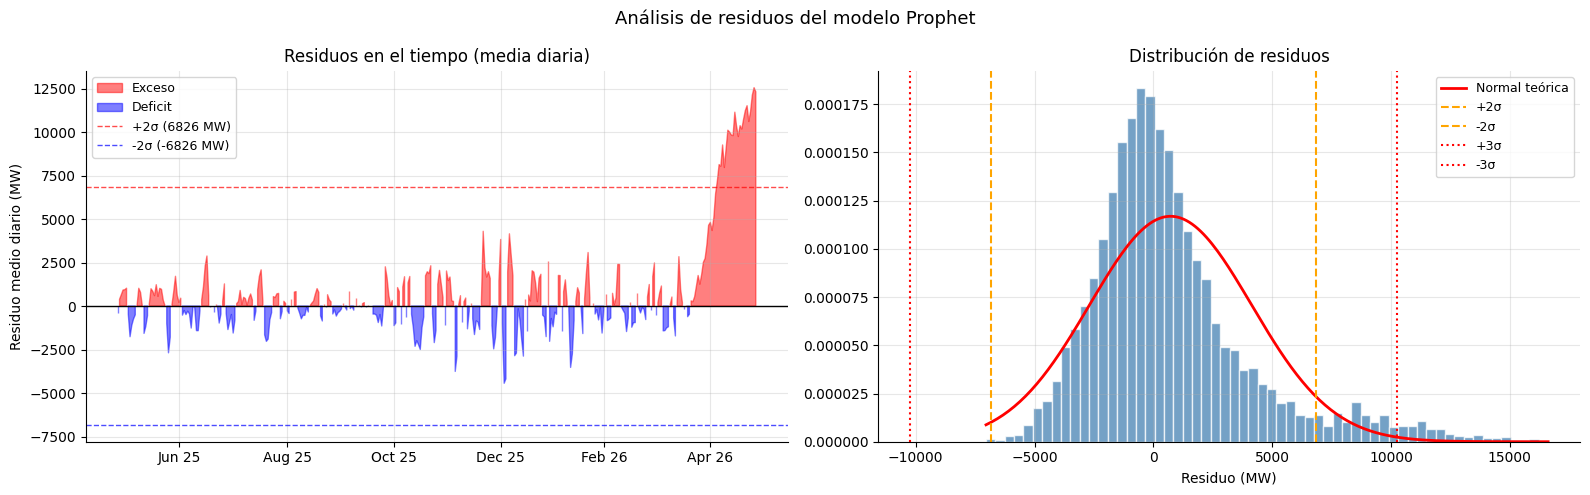

sigma (1σ) = 3413 MW  |  2σ = 6826 MW  |  3σ = 10239 MW


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Análisis de residuos del modelo Prophet', fontsize=13)

# Serie temporal de residuos
ax = axes[0]
residuos_diarios = df['residuo_mw'].resample('1D').mean()
ax.fill_between(residuos_diarios.index, residuos_diarios, 0,
                where=residuos_diarios > 0, alpha=0.5, color='red',   label='Exceso')
ax.fill_between(residuos_diarios.index, residuos_diarios, 0,
                where=residuos_diarios < 0, alpha=0.5, color='blue',  label='Deficit')
ax.axhline(0, color='black', linewidth=1)

sigma = df['residuo_mw'].std()
ax.axhline( 2*sigma, color='red',  linestyle='--', linewidth=1, alpha=0.7, label=f'+2σ ({2*sigma:.0f} MW)')
ax.axhline(-2*sigma, color='blue', linestyle='--', linewidth=1, alpha=0.7, label=f'-2σ ({-2*sigma:.0f} MW)')
ax.set_ylabel('Residuo medio diario (MW)')
ax.set_title('Residuos en el tiempo (media diaria)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(fontsize=9)

# Histograma de residuos
ax2 = axes[1]
ax2.hist(df['residuo_mw'], bins=60, color='steelblue', alpha=0.75, edgecolor='white', density=True)
# Curva normal teórica
from scipy import stats
x = np.linspace(df['residuo_mw'].min(), df['residuo_mw'].max(), 200)
ax2.plot(x, stats.norm.pdf(x, df['residuo_mw'].mean(), sigma),
         'r-', linewidth=2, label='Normal teórica')
ax2.axvline( 2*sigma, color='orange', linestyle='--', label=f'+2σ')
ax2.axvline(-2*sigma, color='orange', linestyle='--', label=f'-2σ')
ax2.axvline( 3*sigma, color='red',    linestyle=':',  label=f'+3σ')
ax2.axvline(-3*sigma, color='red',    linestyle=':',  label=f'-3σ')
ax2.set_xlabel('Residuo (MW)')
ax2.set_title('Distribución de residuos')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('04_residuos.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'sigma (1σ) = {sigma:.0f} MW  |  2σ = {2*sigma:.0f} MW  |  3σ = {3*sigma:.0f} MW')

## 3. Método 1: Z-score sobre residuos

El **Z-score** estandariza el residuo dividiéndolo entre la desviación estándar:

```
Z = (residuo - media_residuos) / std_residuos
```

Un Z-score de 2.5 significa que el error es 2.5 veces mayor que el error típico.

**Umbral:** |Z| > 2.5 → anomalía (aproximadamente el 1.2% de los puntos)

> Esta es la forma más natural de detección cuando tienes un buen modelo
> predictivo: defines anomalía como "error de predicción extraordinariamente grande".


Anomalias Z-score (|Z|>2.5): 318 de 8751 puntos (3.6%)
  Exceso:  318 puntos
  Deficit: 0 puntos


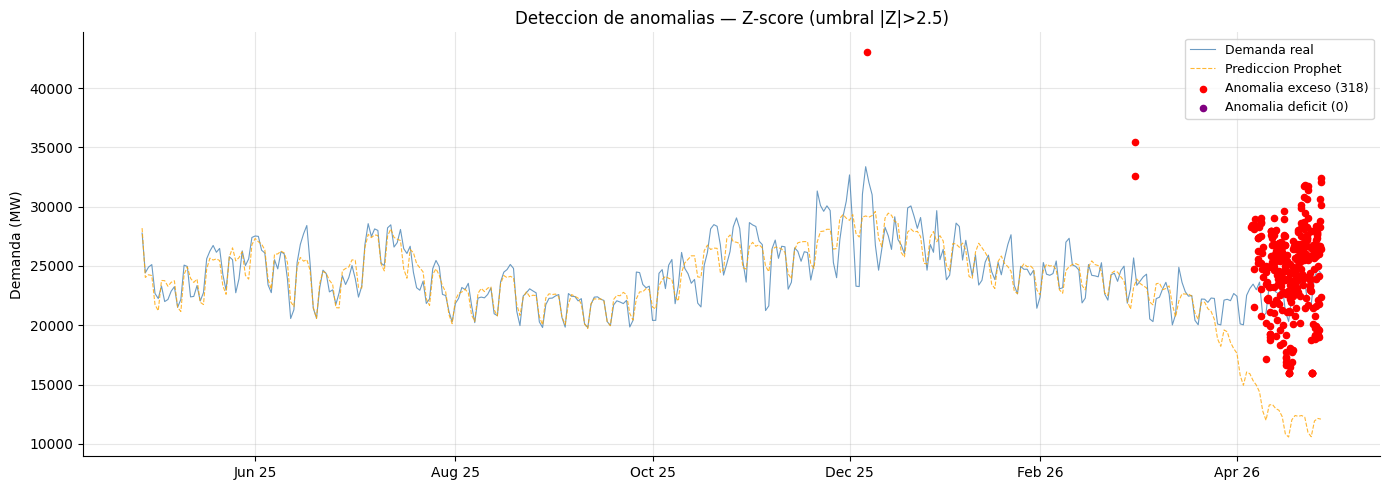

In [4]:
UMBRAL_Z = 2.5

# Calcular Z-score
media_res = df['residuo_mw'].mean()
std_res   = df['residuo_mw'].std()
df['z_score']          = (df['residuo_mw'] - media_res) / std_res
df['anomalia_zscore']  = df['z_score'].abs() > UMBRAL_Z
df['tipo_zscore']      = np.where(df['z_score'] >  UMBRAL_Z, 'exceso',
                         np.where(df['z_score'] < -UMBRAL_Z, 'deficit', 'normal'))

n_anomalias = df['anomalia_zscore'].sum()
pct         = n_anomalias / len(df) * 100
print(f'Anomalias Z-score (|Z|>{UMBRAL_Z}): {n_anomalias} de {len(df)} puntos ({pct:.1f}%)')
print(f'  Exceso:  {(df["tipo_zscore"]=="exceso").sum()} puntos')
print(f'  Deficit: {(df["tipo_zscore"]=="deficit").sum()} puntos')

# Visualizar
fig, ax = plt.subplots(figsize=(14, 5))
dem_diaria = df['demand_mw'].resample('1D').mean()
pred_diaria = df['demand_pred'].resample('1D').mean()

ax.plot(dem_diaria.index,  dem_diaria.values,  color='steelblue', linewidth=0.8,
        alpha=0.8, label='Demanda real')
ax.plot(pred_diaria.index, pred_diaria.values, color='orange', linewidth=0.8,
        linestyle='--', alpha=0.8, label='Prediccion Prophet')

# Marcar anomalías
anom = df[df['anomalia_zscore']]
exceso  = anom[anom['tipo_zscore'] == 'exceso']
deficit = anom[anom['tipo_zscore'] == 'deficit']
ax.scatter(exceso.index,  exceso['demand_mw'],  color='red',   s=20, zorder=5,
           label=f'Anomalia exceso ({len(exceso)})')
ax.scatter(deficit.index, deficit['demand_mw'], color='purple', s=20, zorder=5,
           label=f'Anomalia deficit ({len(deficit)})')

ax.set_ylabel('Demanda (MW)')
ax.set_title(f'Deteccion de anomalias — Z-score (umbral |Z|>{UMBRAL_Z})')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig('04_anomalias_zscore.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Método 2: Isolation Forest

El **Isolation Forest** es un algoritmo de Machine Learning que detecta anomalías
de forma diferente: construye árboles de decisión aleatorios y mide cuántos
cortes hacen falta para "aislar" cada punto.

- Los puntos **normales** están agrupados → necesitan muchos cortes para aislarlos
- Los puntos **anómalos** están separados → se aíslan con pocos cortes

No necesita un modelo predictivo previo — trabaja directamente con las variables.
Esto lo hace útil para detectar **combinaciones raras** de variables:
"temperatura de 20°C con demanda de 35.000 MW nunca lo hemos visto".

**Parámetro clave:** `contamination` — qué fracción de puntos esperamos que sean anomalías.


Anomalias Isolation Forest (contaminacion=0.02): 175 puntos (2.0%)


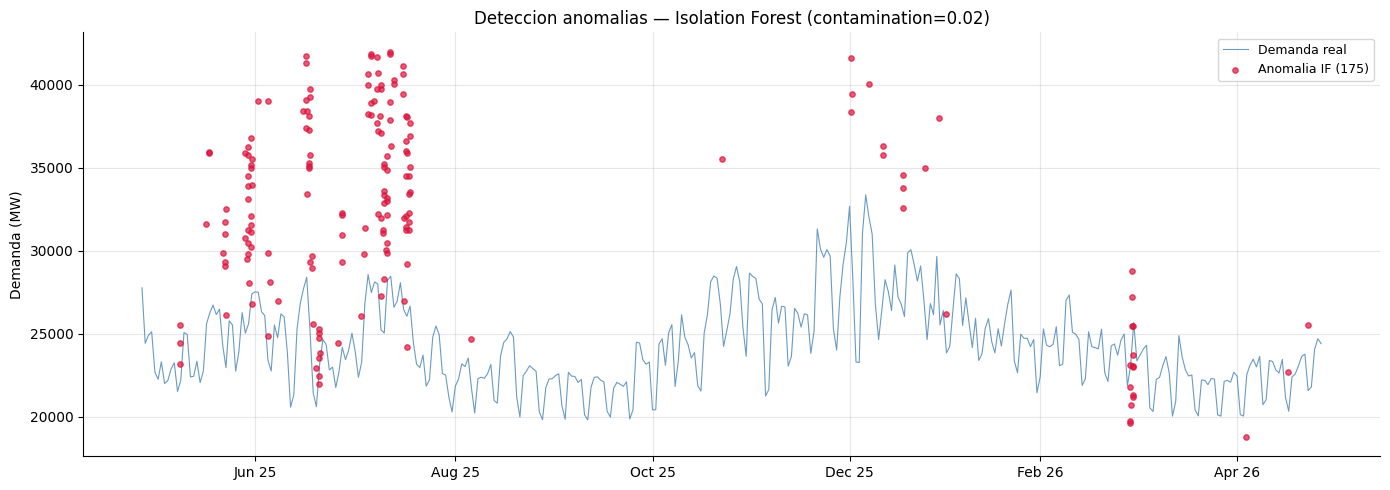

In [5]:
CONTAMINATION = 0.02   # esperamos que el 2% de los puntos sean anomalías

features = ['demand_mw', 'temperature_c', 'humidity_pct',
            'wind_speed_kmh', 'solar_radiation_wm2', 'hour', 'is_weekend']

df_feat = df[features].copy()
df_feat['is_weekend'] = df_feat['is_weekend'].astype(float)
df_feat = df_feat.dropna()

# Normalizar (Isolation Forest es sensible a la escala)
scaler = StandardScaler()
X = scaler.fit_transform(df_feat)

# Entrenar y predecir
iforest = IsolationForest(
    n_estimators=200,
    contamination=CONTAMINATION,
    random_state=42,
    n_jobs=-1,
)
pred_iforest = iforest.fit_predict(X)   # -1 = anomalia, 1 = normal
scores       = iforest.score_samples(X) # puntuacion de anomalia (mas negativo = mas raro)

df_feat['anomalia_iforest'] = pred_iforest == -1
df_feat['iforest_score']    = scores

# Copiar al DataFrame principal
df['anomalia_iforest'] = False
df['iforest_score']    = np.nan
df.loc[df_feat.index, 'anomalia_iforest'] = df_feat['anomalia_iforest']
df.loc[df_feat.index, 'iforest_score']    = df_feat['iforest_score']

n_if = df['anomalia_iforest'].sum()
print(f'Anomalias Isolation Forest (contaminacion={CONTAMINATION}): {n_if} puntos ({n_if/len(df)*100:.1f}%)')

# Visualizar
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dem_diaria.index, dem_diaria.values, color='steelblue', linewidth=0.8,
        alpha=0.8, label='Demanda real')

anom_if = df[df['anomalia_iforest']]
ax.scatter(anom_if.index, anom_if['demand_mw'], color='crimson', s=15, zorder=5,
           alpha=0.7, label=f'Anomalia IF ({n_if})')
ax.set_ylabel('Demanda (MW)')
ax.set_title(f'Deteccion anomalias — Isolation Forest (contamination={CONTAMINATION})')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('04_anomalias_iforest.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Comparativa: ¿coinciden los dos métodos?

El mejor indicador de una anomalía real es cuando **ambos métodos la detectan**.
Si solo la detecta uno, puede ser un falso positivo.

Definimos tres niveles de confianza:
- 🔴 **Alta confianza** — detectada por Z-score Y por Isolation Forest
- 🟡 **Media confianza** — detectada solo por uno de los dos
- ⚪ **Normal** — ninguno la detecta


Resumen de coincidencias:
  Alta confianza (ambos):               2 puntos
  Solo Z-score:                       316 puntos
  Solo Isolation Forest:              173 puntos
  Total anomalias unicas:             491 puntos


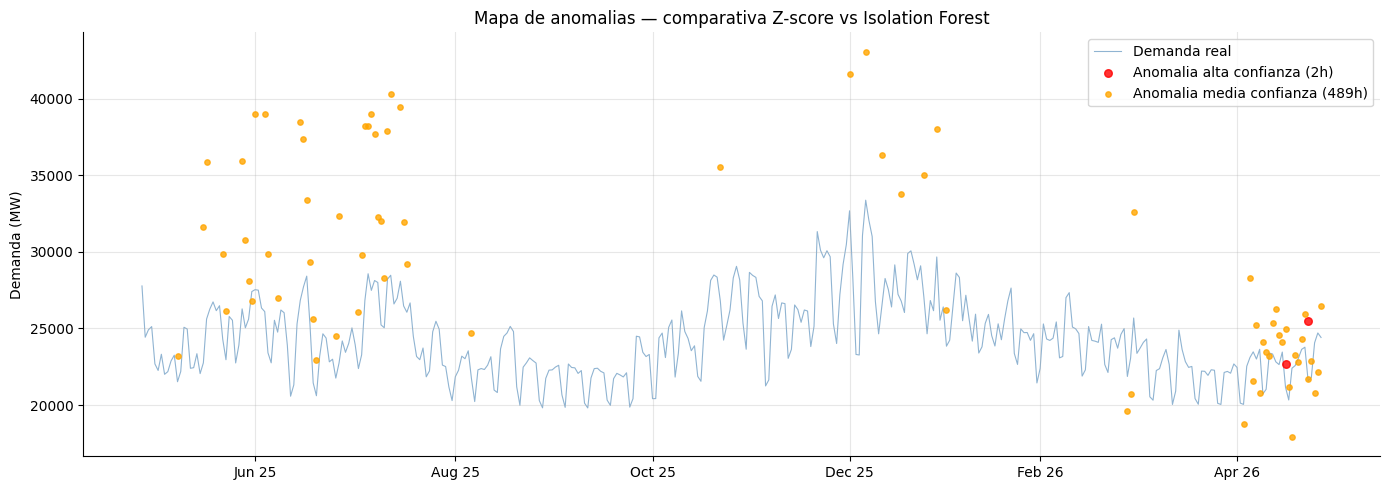

In [6]:
df['ambos']         = df['anomalia_zscore'] & df['anomalia_iforest']
df['solo_zscore']   = df['anomalia_zscore'] & ~df['anomalia_iforest']
df['solo_iforest']  = df['anomalia_iforest'] & ~df['anomalia_zscore']
df['nivel_anomalia'] = np.where(df['ambos'],        'alta',
                       np.where(df['anomalia_zscore'] | df['anomalia_iforest'], 'media', 'normal'))

print('Resumen de coincidencias:')
print(f'  Alta confianza (ambos):           {df["ambos"].sum():>5} puntos')
print(f'  Solo Z-score:                     {df["solo_zscore"].sum():>5} puntos')
print(f'  Solo Isolation Forest:            {df["solo_iforest"].sum():>5} puntos')
print(f'  Total anomalias unicas:           {(df["anomalia_zscore"] | df["anomalia_iforest"]).sum():>5} puntos')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dem_diaria.index, dem_diaria.values, color='steelblue', linewidth=0.8,
        alpha=0.6, label='Demanda real', zorder=1)

colores_nivel = {'alta': 'red', 'media': 'orange'}
for nivel, color in colores_nivel.items():
    pts = df[df['nivel_anomalia'] == nivel]
    pts_dia = pts.resample('1D').first().dropna(subset=['demand_mw'])
    ax.scatter(pts_dia.index, pts_dia['demand_mw'],
               color=color, s=30 if nivel=='alta' else 15,
               zorder=5, alpha=0.8,
               label=f'Anomalia {nivel} confianza ({len(pts)}h)')

ax.set_ylabel('Demanda (MW)')
ax.set_title('Mapa de anomalias — comparativa Z-score vs Isolation Forest')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('04_comparativa.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Inspección de las anomalías más extremas

¿Cuáles son los momentos más anómalos del año? Inspeccionamos los 10 peores.


In [7]:
# Top 10 anomalías por Z-score absoluto
top10 = df.nlargest(10, 'z_score')[
    ['demand_mw', 'demand_pred', 'residuo_mw', 'z_score',
     'temperature_c', 'hour', 'nivel_anomalia']
].copy()
top10.index = top10.index.strftime('%Y-%m-%d %H:%M')
top10.columns = ['Real (MW)', 'Predicho (MW)', 'Residuo (MW)', 'Z-score',
                 'Temp (C)', 'Hora', 'Nivel']
top10[['Real (MW)', 'Predicho (MW)', 'Residuo (MW)']] = top10[
    ['Real (MW)', 'Predicho (MW)', 'Residuo (MW)']].round(0).astype(int)
top10['Z-score'] = top10['Z-score'].round(2)
top10['Temp (C)'] = top10['Temp (C)'].round(1)

print('Top 10 anomalias de EXCESO (demanda mucho mayor de lo esperado):')
display(top10)

print()
bot10 = df.nsmallest(10, 'z_score')[
    ['demand_mw', 'demand_pred', 'residuo_mw', 'z_score',
     'temperature_c', 'hour', 'nivel_anomalia']
].copy()
bot10.index = bot10.index.strftime('%Y-%m-%d %H:%M')
bot10.columns = ['Real (MW)', 'Predicho (MW)', 'Residuo (MW)', 'Z-score',
                 'Temp (C)', 'Hora', 'Nivel']
bot10[['Real (MW)', 'Predicho (MW)', 'Residuo (MW)']] = bot10[
    ['Real (MW)', 'Predicho (MW)', 'Residuo (MW)']].round(0).astype(int)
bot10['Z-score'] = bot10['Z-score'].round(2)
bot10['Temp (C)'] = bot10['Temp (C)'].round(1)
print('Top 10 anomalias de DEFICIT (demanda mucho menor de lo esperado):')
display(bot10)

Top 10 anomalias de EXCESO (demanda mucho mayor de lo esperado):


,Real (MW),Predicho (MW),Residuo (MW),Z-score,Temp (C),Hora,Nivel
timestamp,,,,,,,
2026-05-26 22:00,32430,15813,16616,4.66,31.3,22,media
2026-05-26 21:00,32079,15514,16565,4.64,31.8,21,media
2026-05-22 20:00,30680,14509,16171,4.53,32.0,20,media
2026-05-26 20:00,30647,14526,16121,4.51,31.9,20,media
2026-05-22 22:00,31702,15675,16027,4.48,30.7,22,media
2026-05-22 21:00,31377,15441,15936,4.46,31.5,21,media
2026-05-21 20:00,30793,14968,15825,4.42,31.7,20,media
2026-05-21 21:00,31771,15975,15796,4.42,31.4,21,media
2026-05-21 22:00,31864,16285,15578,4.35,30.8,22,media



Top 10 anomalias de DEFICIT (demanda mucho menor de lo esperado):


,Real (MW),Predicho (MW),Residuo (MW),Z-score,Temp (C),Hora,Nivel
timestamp,,,,,,,
2026-01-04 19:00,24677,31720,-7043,-2.28,10.9,19,normal
2026-01-04 18:00,22996,30009,-7013,-2.27,11.6,18,normal
2026-01-04 16:00,21883,28743,-6860,-2.22,11.2,16,normal
2026-01-03 19:00,23875,30678,-6803,-2.21,11.5,19,normal
2026-01-03 18:00,22572,29138,-6566,-2.14,12.1,18,normal
2026-01-04 17:00,22429,28933,-6504,-2.12,11.5,17,normal
2026-01-04 21:00,27403,33855,-6452,-2.10,8.1,21,normal
2025-12-28 18:00,22918,29158,-6240,-2.04,10.8,18,normal
2025-08-16 11:00,21410,27647,-6237,-2.04,25.3,11,normal


## 7. Guardar anomalías en InfluxDB

Escribimos las anomalías detectadas en InfluxDB para visualizarlas en Grafana.

Schema del measurement `anomalies`:
- `residual_mw` — diferencia real vs predicción
- `z_score` — score normalizado
- `iforest_score` — puntuación Isolation Forest (más negativo = más anómalo)
- `nivel` (tag) — `alta`, `media`, `normal`


In [8]:
from ingestion.influx_writer import _get_client, _parse_ts
from influxdb_client import Point, WritePrecision
from influxdb_client.client.write_api import SYNCHRONOUS
from dotenv import load_dotenv
load_dotenv(os.path.join('..', '.env'))
import os as _os

bucket = _os.getenv('INFLUX_BUCKET', 'gemelo_digital')

# Solo escribir puntos con anomalía o con scores útiles (cada hora, no todos)
df_write = df.resample('1h').first().dropna(subset=['z_score'])

points = []
for ts, row in df_write.iterrows():
    ts_utc = ts.tz_convert('UTC').tz_localize(None).to_pydatetime()
    p = (
        Point("anomalies")
        .tag("nivel",  row['nivel_anomalia'])
        .tag("region", "peninsular")
        .field("residual_mw",   float(row['residuo_mw']))
        .field("z_score",       float(row['z_score']))
        .field("iforest_score", float(row['iforest_score']) if not pd.isna(row['iforest_score']) else 0.0)
        .field("is_anomaly",    int(row['nivel_anomalia'] != 'normal'))
        .time(ts_utc, WritePrecision.S)
    )
    points.append(p)

with _get_client() as client:
    client.write_api(write_options=SYNCHRONOUS).write(bucket=bucket, record=points)

n_anom_escritas = df_write[df_write['nivel_anomalia'] != 'normal'].shape[0]
print(f'Escritos {len(points)} puntos en measurement "anomalies"')
print(f'  De los cuales {n_anom_escritas} son anomalias ({n_anom_escritas/len(points)*100:.1f}%)')
print('Ahora visibles en Grafana.')

Escritos 8751 puntos en measurement "anomalies"
  De los cuales 491 son anomalias (5.6%)
Ahora visibles en Grafana.


## 8. Conclusiones

### Lo que aprendimos

| Concepto | Clave del proyecto |
|----------|-------------------|
| **Residuo** | La "sorpresa" del modelo: cuánto se equivocó respecto a la realidad |
| **Z-score** | Normaliza el error — detecta los más extremos estadísticamente |
| **Isolation Forest** | Detecta combinaciones inusuales de variables sin necesitar predicción |
| **Doble detección** | Más confianza cuando ambos métodos coinciden |

### El loop del gemelo digital está completo

```
Sensores (Open-Meteo + REE)
        ↓
Ingestión (collector.py cada 10 min)
        ↓
Almacenamiento (InfluxDB)
        ↓
Análisis (Jupyter notebooks)
        ↓
Predicción (Prophet)          ← Fase 5
        ↓
Detección de anomalías        ← Fase 6  ← estás aquí
        ↓
Visualización (Grafana)
        ↓
Alerta cuando anomalía alta confianza
```

Con datos ESIOS reales, las anomalías detectadas corresponderán a eventos
reales: olas de calor, apagones, festivos, eventos masivos.
